# I.4 — Intra-channel homogeneity of pump targets

**Objective (brief I.4).** [A1] (§4.3) observes that the coins pumped by one channel look alike (similar market
capitalisation, Alexa rank, Reddit audience) while different channels pick different kinds of coins. The paper shows
scatter plots but no statistic. We turn the observation into a test.

**Definitions.** For target $c$ (three days before the pump) let
$$\boldsymbol x_c=\big(\log \mathrm{mcap},\ \log \mathrm{price},\ \log \mathrm{volume},\ \log(1+\mathrm{twitter}),\
\log(1+\mathrm{reddit})\big)$$
with every component standardised across targets ($z$-score), so $\cos$ compares profiles relative to the average
target. For channel $h$ with $n_h\ge2$ targets $c_1,\dots,c_{n_h}$:
$$S_{\text{intra}}(h)=\binom{n_h}{2}^{-1}\sum_{i<j}\cos(\boldsymbol x_{c_i},\boldsymbol x_{c_j}),\qquad
\cos(\boldsymbol u,\boldsymbol v)=\frac{\boldsymbol u^\top\boldsymbol v}{\lVert\boldsymbol u\rVert\,\lVert\boldsymbol v\rVert},$$
and the overall statistic is the average over the $H$ eligible channels, $\bar S=\frac1H\sum_h S_{\text{intra}}(h)$.

**Permutation test.** $H_0$: the channel label carries no information about the target profile (labels are
exchangeable). Under $H_0$, permuting the labels across targets (keeping each channel's size) gives draws
$\bar S^{(b)}$, $b=1..B$, from the null distribution and
$$\hat p=\frac{1+\#\{b:\bar S^{(b)}\ge\bar S\}}{B+1}.$$
Adding one to numerator and denominator counts the observed labelling as one of the permutations, which makes the
test exact (size $\le\alpha$) and never returns $\hat p=0$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pnd_paper import settings
from pnd_paper import stats as S
from pnd_paper.data import pd_log, coingecko
from pnd_paper.report import Reporter, md, show, close, SERIES, seq_cmap

settings.seed_everything()
R = Reporter("I4_intra_channel_homogeneity")
B = settings.SIZES.perm_draws
md(f"Permutation draws: **B = {B:,}** ({'QUICK' if settings.QUICK else 'FULL'} run; the brief asks for 10 000).")

Permutation draws: **B = 1,000** (QUICK run; the brief asks for 10 000).

## 1. Target profiles

In [2]:
log = pd_log.load_pd_log()
log["pump_date"] = log.timestamp.dt.tz_localize(None).dt.normalize()
tg = coingecko.load_targets()
df = log.merge(tg, on=["coin", "pump_date"], how="inner")
df = df.drop_duplicates(["channel_id", "coin", "pump_date"])
feat = pd.DataFrame({
    "log mcap": np.log(df.market_cap_usd.where(df.market_cap_usd > 0)),
    "log price": np.log(df.price_usd.where(df.price_usd > 0)),
    "log volume": np.log(df.volume_usd.where(df.volume_usd > 0)),
    "log twitter": np.log1p(df.twitter_followers),
    "log reddit": np.log1p(df.reddit_subscribers),
})
ok = feat.notna().all(axis=1)
df, feat = df[ok].reset_index(drop=True), feat[ok].reset_index(drop=True)
Z = ((feat - feat.mean()) / feat.std()).values
df["channel"] = df.channel_id.map(pd_log.channel_labels(log.channel_id))
sizes = df.channel.value_counts()
elig = sizes[sizes >= 2].index
keep = df.channel.isin(elig).values
df, Z = df[keep].reset_index(drop=True), Z[keep]
md(f"Targets with all five CoinGecko features: **n = {len(df)}** rows in **H = {len(elig)}** channels with "
   f"$n_h\\ge2$ (median $n_h$ = {sizes[elig].median():.0f}).")
show(feat.describe().T[["mean", "std", "min", "max"]])

Targets with all five CoinGecko features: **n = 743** rows in **H = 85** channels with $n_h\ge2$ (median $n_h$ = 4).

,mean,std,min,max
log mcap,16.56,1.139,13.36,21.48
log price,-2.063,1.753,-6.964,2.834
log volume,13.77,1.86,6.275,19.73
log twitter,10.11,1.232,1.946,12.73
log reddit,8.402,0.9869,4.771,12.15


## 2. Observed statistic and permutation null

With $M_{ij}=\cos(\boldsymbol x_i,\boldsymbol x_j)$ and the one-hot channel matrix $A\in\{0,1\}^{n\times H}$, the
sum of within-channel pairs is $\tfrac12\big[(A^\top MA)_{hh}-\sum_{i\in h}M_{ii}\big]$, so each permutation
costs one matrix product. The **sensitivity variant** drops pairs of the *same* coin ($\cos$ close to 1 when a
channel re-pumps a coin), so that the homogeneity cannot come only from re-pumps.

In [3]:
U = Z / np.linalg.norm(Z, axis=1, keepdims=True)
M = U @ U.T
same_coin = (df.coin.values[:, None] == df.coin.values[None, :]).astype(float)
codes, chans = pd.factorize(df.channel)
A = np.zeros((len(df), len(chans)))
A[np.arange(len(df)), codes] = 1.0


def intra(Mw, W, A):
    """Per-channel mean pairwise similarity, with pair weights W (1 = pair counted)."""
    MW = Mw * W
    num = (A * (MW @ A)).sum(0) - A.T @ np.diag(MW)
    den = (A * (W @ A)).sum(0) - A.T @ np.diag(W)
    with np.errstate(invalid="ignore", divide="ignore"):
        return num / den


rng = np.random.default_rng(settings.SEED)
variants = {"all pairs": np.ones_like(M), "excluding same-coin pairs": 1.0 - same_coin}
out, nulls, per_ch_null = {}, {}, {}
for name, W in variants.items():
    obs = intra(M, W, A)
    sbar = np.nanmean(obs)
    draws = np.empty(B)
    ch_draws = np.empty((B, len(chans)))
    for b in range(B):
        Ap = A[rng.permutation(len(df))]
        s = intra(M, W, Ap)
        ch_draws[b] = s
        draws[b] = np.nanmean(s)
    out[name] = (obs, sbar)
    nulls[name] = draws
    per_ch_null[name] = ch_draws

all_pairs = M[np.triu_indices(len(df), 1)]
diff_ch = (codes[:, None] != codes[None, :])[np.triu_indices(len(df), 1)]
summary = []
for name in variants:
    obs, sbar = out[name]
    d = nulls[name]
    summary.append({"variant": name, "S_bar (observed)": sbar, "null mean": d.mean(), "null sd": d.std(ddof=1),
                    "z = (S - mean)/sd": (sbar - d.mean()) / d.std(ddof=1), "p_hat": S.monte_carlo_p(sbar, d), "B": B})
summary = pd.DataFrame(summary).set_index("variant")
R.table(summary, "permutation_test")
show(summary)
for name, rw in summary.iterrows():
    md(f"- **{name}**: $\\bar S={rw['S_bar (observed)']:.3f}$ versus $\\mathbb E_{{H_0}}[\\bar S]={rw['null mean']:.3f}$ "
       f"(sd {rw['null sd']:.3f}), standardised effect $z={rw['z = (S - mean)/sd']:.1f}$, "
       f"$\\hat p={rw['p_hat']:.4g}$ → {S.decision(rw['p_hat'])}. "
       + ("The smallest attainable value is $1/(B+1)$, so the result is as significant as $B$ allows."
          if rw['p_hat'] <= 1.0 / (B + 1) + 1e-12 else ""))
md(f"Mean cosine of targets of the **same** channel: {all_pairs[~diff_ch].mean():.3f}; of **different** channels: "
   f"{all_pairs[diff_ch].mean():.3f}. ([A1] §4.2 reports 0.92 vs 0.80 for word-embedding similarities, a different "
   "representation of coins, so only the ordering is comparable.)")

,S_bar (observed),null mean,null sd,z = (S - mean)/sd,p_hat,B
variant,,,,,,
all pairs,0.1003,0.00605,0.03208,2.94,0.002997,1000
excluding same-coin pairs,0.07433,-0.008612,0.03034,2.734,0.002997,1000


- **all pairs**: $\bar S=0.100$ versus $\mathbb E_{H_0}[\bar S]=0.006$ (sd 0.032), standardised effect $z=2.9$, $\hat p=0.002997$ → reject $H_0$ at $\alpha=0.05$. 

- **excluding same-coin pairs**: $\bar S=0.074$ versus $\mathbb E_{H_0}[\bar S]=-0.009$ (sd 0.030), standardised effect $z=2.7$, $\hat p=0.002997$ → reject $H_0$ at $\alpha=0.05$. 

Mean cosine of targets of the **same** channel: 0.069; of **different** channels: 0.005. ([A1] §4.2 reports 0.92 vs 0.80 for word-embedding similarities, a different representation of coins, so only the ordering is comparable.)

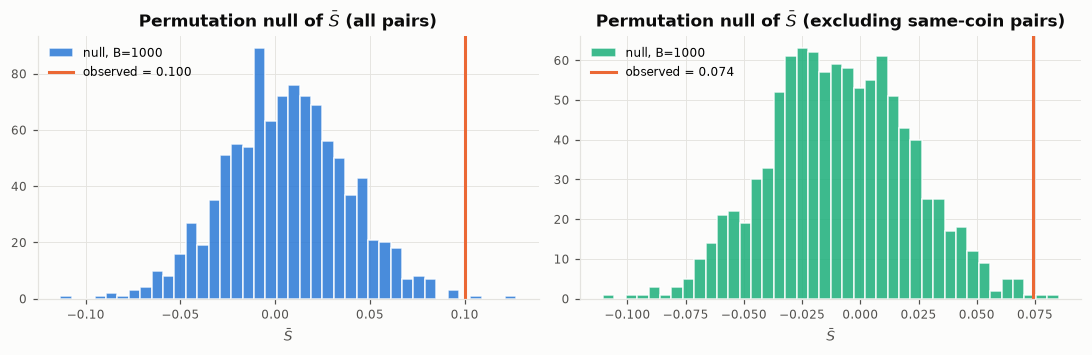

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, name, c in zip(axes, variants, (SERIES[0], SERIES[2])):
    ax.hist(nulls[name], bins=40, color=c, alpha=0.85, edgecolor="white", label=f"null, B={B}")
    ax.axvline(out[name][1], color=SERIES[1], lw=2, label=f"observed = {out[name][1]:.3f}")
    ax.set_title(f"Permutation null of $\\bar S$ ({name})")
    ax.set_xlabel(r"$\bar S$")
    ax.legend()
R.fig(fig, "permutation_null")
close(fig)

## 3. Which channels are homogeneous? (multiple testing)

For each channel the same draws give $\hat p_h=(1+\#\{b:S^{(b)}_{\text{intra}}(h)\ge S_{\text{intra}}(h)\})/(B+1)$.
Testing $H$ channels at once inflates false discoveries; the **Benjamini–Hochberg** procedure controls the false
discovery rate: sort $\hat p_{(1)}\le\dots\le\hat p_{(H)}$ and reject the $k$ smallest where
$k=\max\{j:\hat p_{(j)}\le jq/H\}$, here $q=0.05$.

In [5]:
obs, _ = out["all pairs"]
pch = np.array([S.monte_carlo_p(obs[h], per_ch_null["all pairs"][:, h]) for h in range(len(chans))])
qch = S.benjamini_hochberg(pch)
per = pd.DataFrame({"channel": chans, "n_h": A.sum(0).astype(int), "S_intra": obs, "p_hat": pch, "q_BH": qch}) \
    .sort_values("S_intra", ascending=False)
R.table(per, "per_channel", index=False)
show(per.head(15).set_index("channel"))
md(f"{(per.q_BH < 0.05).sum()} of {len(per)} channels are individually homogeneous at FDR 5 % "
   f"({(per.p_hat < 0.05).sum()} at the unadjusted 5 % level). Small channels have little power: with $n_h=2$ a "
   "single pair decides the statistic.")

,n_h,S_intra,p_hat,q_BH
channel,,,,
Ch-086,2,0.9791,0.006993,0.0743
Ch-104,4,0.9192,0.000999,0.04246
Ch-016,2,0.8532,0.04096,0.2176
Ch-087,4,0.8317,0.001998,0.04246
Ch-066,4,0.8019,0.001998,0.04246
Ch-102,2,0.8011,0.05694,0.242
Ch-008,2,0.676,0.1169,0.3777
Ch-018,2,0.6359,0.1269,0.3777
Ch-014,5,0.5837,0.004995,0.07076


4 of 85 channels are individually homogeneous at FDR 5 % (18 at the unadjusted 5 % level). Small channels have little power: with $n_h=2$ a single pair decides the statistic.

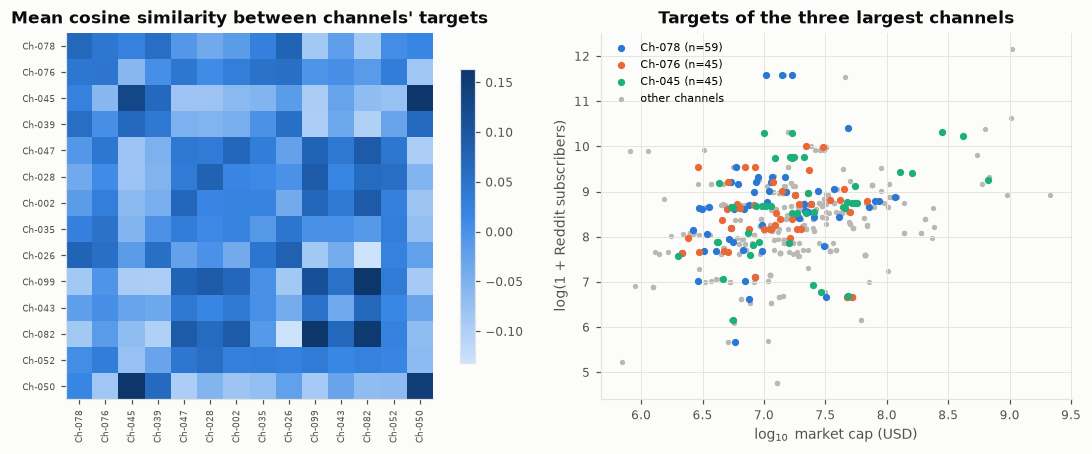

In [6]:
top = per.sort_values("n_h", ascending=False).head(14).channel.tolist()
idx = [np.where(df.channel.values == c)[0] for c in top]
H = np.array([[M[np.ix_(a, b)][~np.eye(len(a), dtype=bool)].mean() if i == j else M[np.ix_(a, b)].mean()
               for j, b in enumerate(idx)] for i, a in enumerate(idx)])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(H, cmap=seq_cmap(), vmin=np.nanmin(H), vmax=np.nanmax(H))
axes[0].set_xticks(range(len(top)), top, rotation=90, fontsize=6)
axes[0].set_yticks(range(len(top)), top, fontsize=6)
axes[0].set_title("Mean cosine similarity between channels' targets")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], shrink=0.8)
pts = df.assign(lm=np.log10(df.market_cap_usd), lr=np.log1p(df.reddit_subscribers))
for c, color in zip(top[:3], SERIES[:3]):
    s = pts[pts.channel == c]
    axes[1].scatter(s.lm, s.lr, s=14, color=color, label=f"{c} (n={len(s)})")
rest = pts[~pts.channel.isin(top[:3])]
axes[1].scatter(rest.lm, rest.lr, s=6, color="#b9b8b2", label="other channels", zorder=0)
axes[1].set_xlabel(r"$\log_{10}$ market cap (USD)")
axes[1].set_ylabel("log(1 + Reddit subscribers)")
axes[1].set_title("Targets of the three largest channels")
axes[1].legend(fontsize=7)
R.fig(fig, "channel_heatmap")
close(fig)

## 4. Interpretation (QUICK run, B = 1 000)

* **The paper's qualitative claim survives a formal test.** The observed $\bar S\approx0.10$ lies about three null
  standard deviations above the permutation mean ($\approx0$), and only 2 of the 1 000 permuted labellings reach
  it ($\hat p=3/1001\approx0.003$). $H_0$ "channel labels carry no information about target profiles" is rejected at
  the 1 % level. Excluding pairs of the same coin barely changes the result ($\hat p\approx0.003$), so homogeneity
  is not just a consequence of re-pumps.
* **The effect is real but moderate in absolute size.** Two targets of the same channel have a mean cosine of
  about 0.07 against 0.005 for two targets of different channels. On five standardised features this is a
  tendency, not a rule: channels have a preferred niche but wander outside it. The paper's 0.92 vs 0.80 figures
  come from word embeddings trained on co-occurrence in Telegram messages, which encode "being mentioned together"
  rather than market profiles. They are not comparable in level.
* **Intra-channel homogeneity** means a channel works in a stable niche (a capitalisation and audience range that
  its members can move). **Inter-channel heterogeneity** means niches differ between channels. Together they
  justify conditioning the prediction on the channel's history (sequence models, II.C) instead of learning one
  global "pumpability" score.
* **Per channel**, 18 of 85 channels are significant at the unadjusted 5 % level but only 4 survive the
  Benjamini–Hochberg correction. Most channels have between 2 and 5 profiled targets, so each test has little
  power; the global statistic pools that weak evidence.

**Limitations.** Features are measured three days before each pump, and coins whose CoinGecko record is incomplete
are excluded. Permutations preserve channel sizes but not timing: channels active in the same period may look alike
because the whole market moved, which a time-stratified permutation would control. With $B=1000$ the p-value is
resolved to about $10^{-3}$; the full run ($B=10\,000$) sharpens it.